# Profitability from selected-event monitoring

Replay each method's actual top-five choices at 100 ms assumed arrival, with no artificial cash/share cap. Quantity and price limits are fixed at observation. Realised simulated partial-basket losses remain; there is no additional imposed failure probability. These are conditional displayed-depth results, not exchange-confirmed profits.

In [1]:
from pathlib import Path
import os
import sys
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/config.py').exists())
sys.path.insert(0, str(ROOT))
import json
import pandas as pd
from IPython.display import display
pd.set_option('display.max_columns', 20)
from src.reporting.workflow import profitability_dataset, profitability_run, execution_path
%matplotlib inline
from matplotlib import pyplot as plt
from src.simulator.profitability import replay_profitability
from src.reporting.profitability import (comparison, plot_profitability, event_returns,
    audit_profitability, build_profitability_report)
from src.reporting.workflow import new_execution_run, select_execution_run
dataset_dir, run_dir = profitability_dataset(), profitability_run()


## Replay controls and primary results

`RUN_REPLAY = True` creates a fresh replay; the default displays completed results. Each policy has an independent ledger that persists across windows and folds. Minimum order size, ticks, profitable worst-limit prices, supported recording coverage and shared-quote reservations apply. Partial baskets are unwound one second after arrival; that period also controls the conservative event hold after complete fills.

The primary metric is total net P&L at N = 5. All-zero prediction error and positive-window capture are secondary diagnostics. Unknown executions are counted beside known subtotals. All methods in these tables use the rebuilt uncapped targets and quote features.

In [2]:
RUN_REPLAY = False
if RUN_REPLAY:
    destination = new_execution_run(run_dir)
    replay_profitability(destination, dataset_dir, run_dir, top_n=5)
    select_execution_run(run_dir, destination)
execution_dir = execution_path(run_dir)
for view in ['book','combined']:
    print('Features:', view)
    display(comparison(run_dir,view=view).round(3))
summary = pd.read_csv(execution_dir / 'summary.csv')
random = summary.loc[summary.scope.eq('all_events') & summary.fold.eq('all') & summary.model.str.match(r'random_\d+$')]
display(random.known_pnl_usd.describe().rename('Twenty random-policy P&Ls'))


Features: book


,known_pnl_usd,completed_profit_usd,partial_pnl_usd,attempts,unknown_attempts,max_drawdown_usd,largest_reserved_cash_usd,cumulative_purchase_cash_usd,recall,precision_known,mae_usd,rmse_usd,selected_unknown
model,,,,,,,,,,,,,
logistic,5902.628,6317.374,-414.746,479,0,206.151,72920.866,1428952.729,0.973,0.048,NaN,NaN,374.0
random_forest,5942.424,6357.170,-414.746,510,0,205.913,72920.866,1461914.933,0.952,0.053,NaN,NaN,1297.0
boosted_trees,5219.192,5633.938,-414.746,510,0,205.913,72920.866,1395164.165,0.944,0.053,NaN,NaN,1367.0
rank_ensemble,5942.016,6356.762,-414.746,513,0,205.913,72920.866,1459862.342,0.965,0.053,NaN,NaN,1165.0
reg_ridge,5604.661,5886.049,-281.388,431,0,142.079,72920.866,1344749.757,0.915,0.044,1.167,8.400,235.0
reg_random_forest,5643.042,6057.288,-414.246,493,0,205.913,52909.793,1358412.915,0.891,0.051,0.514,8.354,1492.0
reg_boosted_trees,5332.909,5549.346,-216.437,391,0,133.994,52909.793,1233655.938,0.649,0.039,0.613,8.457,1755.0
reg_ensemble,5655.876,6068.541,-412.665,453,0,264.961,52909.793,1333544.543,0.870,0.046,0.723,8.316,918.0
two_stage_ridge,5843.245,6255.275,-412.029,444,0,207.161,72920.866,1416752.451,0.822,0.042,0.558,8.151,649.0


Features: combined


,known_pnl_usd,completed_profit_usd,partial_pnl_usd,attempts,unknown_attempts,max_drawdown_usd,largest_reserved_cash_usd,cumulative_purchase_cash_usd,recall,precision_known,mae_usd,rmse_usd,selected_unknown
model,,,,,,,,,,,,,
combined_logistic,5925.458,6340.204,-414.746,477,0,205.913,72920.866,1433432.899,0.931,0.050,NaN,NaN,1086.0
combined_random_forest,5942.708,6357.454,-414.746,513,0,205.913,72920.866,1462056.649,0.957,0.054,NaN,NaN,1409.0
combined_boosted_trees,5929.101,6343.847,-414.746,510,0,205.913,72920.866,1461332.256,0.941,0.053,NaN,NaN,1403.0
combined_rank_ensemble,5939.948,6354.694,-414.746,505,0,205.913,72920.866,1456341.410,0.949,0.053,NaN,NaN,1336.0
combined_reg_ridge,5586.103,5867.491,-281.388,432,0,142.079,72920.866,1341157.315,0.912,0.044,1.224,8.412,315.0
combined_reg_random_forest,5793.761,6208.007,-414.246,488,0,205.913,72920.866,1429611.196,0.891,0.052,0.522,8.355,1534.0
combined_reg_boosted_trees,5271.996,5537.103,-265.107,402,0,133.994,52909.793,1238369.842,0.657,0.040,0.623,8.461,1837.0
combined_reg_ensemble,5842.387,6255.053,-412.665,458,0,205.913,72920.866,1391622.032,0.878,0.048,0.747,8.319,1160.0
combined_two_stage_ridge,5826.676,6238.705,-412.029,424,0,207.161,72920.866,1408855.020,0.787,0.040,0.545,8.142,628.0


count      20.000000
mean     1814.907412
std       446.254987
min       827.259330
25%      1463.751500
50%      1869.455970
75%      2160.354185
max      2422.142800
Name: Twenty random-policy P&Ls, dtype: float64

## P&L paths and differences from the quoted-gap rule

Separate panels compare model families. The second figure subtracts the quoted-gap rule to expose small dollar differences. Completed baskets are valued at guaranteed payout minus purchase cost; partial baskets are accounted for at unwind. These curves are not settled cash balances. Monitor-all can earn less than a shortlist because extra monitoring can also add losing trades.

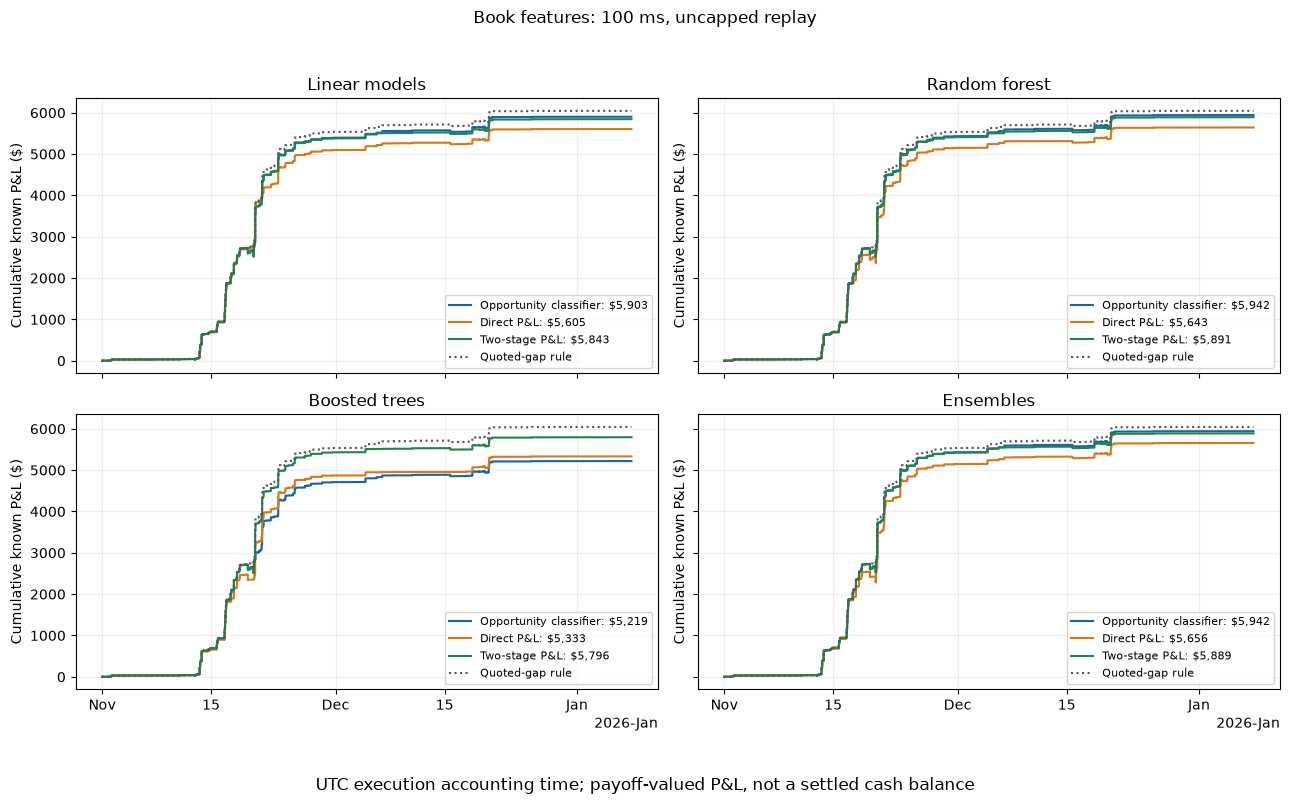

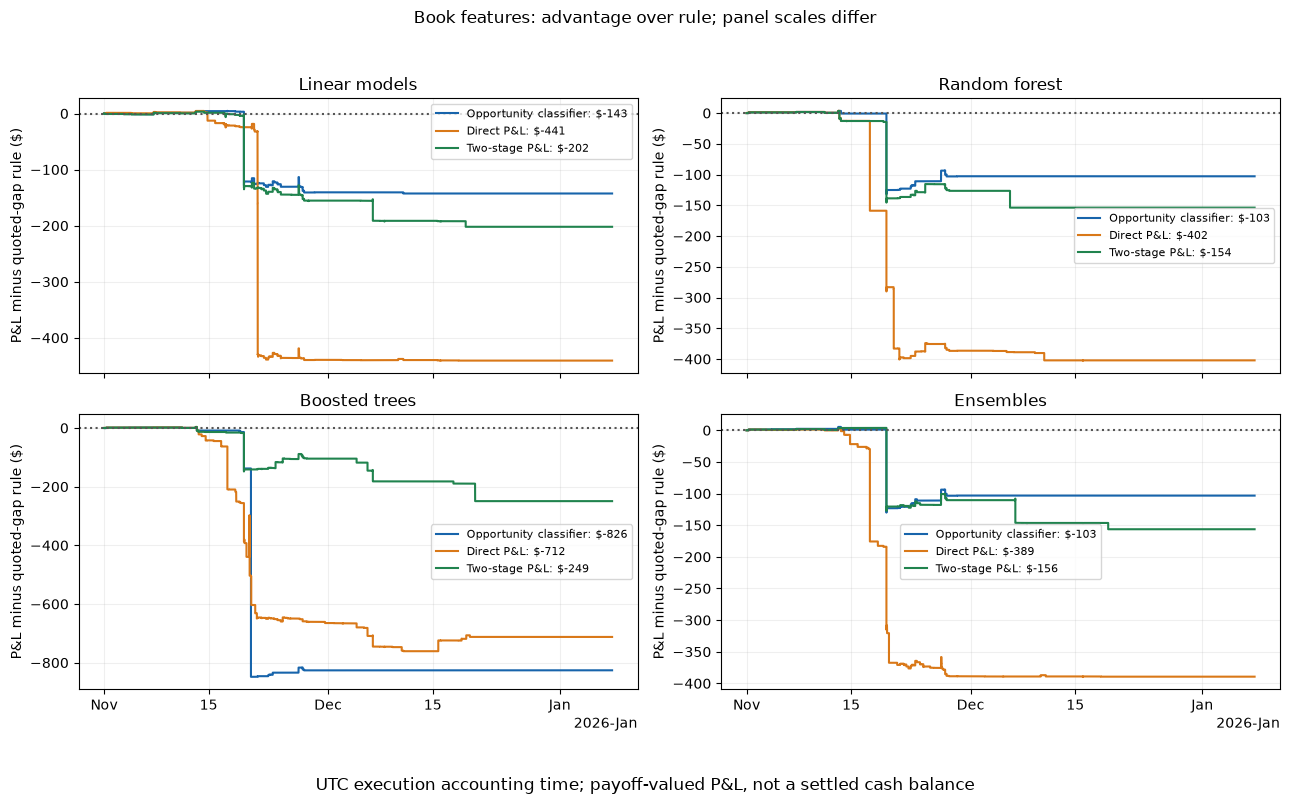

,model,fold,known_pnl_usd,completed_profit_usd,partial_pnl_usd,unknown_attempts
85,logistic,nov_early,4498.149,4788.626,-290.477,0
86,logistic,nov_late,1072.551,1096.479,-23.928,0
87,logistic,dec_late,331.929,432.269,-100.341,0
89,quoted_gap_rule,nov_early,4622.712,4781.911,-159.200,0
90,quoted_gap_rule,nov_late,1090.611,1114.540,-23.928,0
91,quoted_gap_rule,dec_late,331.929,432.269,-100.341,0
181,reg_boosted_trees,nov_early,3976.654,4123.982,-147.328,0
182,reg_boosted_trees,nov_late,975.727,999.656,-23.928,0
183,reg_boosted_trees,dec_late,380.528,425.708,-45.181,0
209,two_stage_boosted_trees,nov_early,4483.408,4773.885,-290.477,0


In [3]:
(run_dir / 'figures').mkdir(exist_ok=True)
for difference, filename in [(False,'pnl.png'),(True,'pnl_difference.png')]:
    fig = plot_profitability(run_dir,difference=difference)
    fig.savefig(run_dir / 'figures' / filename,dpi=160)
    display(fig)
    plt.close(fig)
display(summary.loc[summary.scope.eq('all_events') & summary.fold.ne('all') &
    summary.model.isin(['logistic','reg_boosted_trees','two_stage_boosted_trees','quoted_gap_rule','monitor_all']),
    ['model','fold','known_pnl_usd','completed_profit_usd','partial_pnl_usd','unknown_attempts']].round(3))


## Concentration and generalisation

The next sensitivity excludes the December Fed-decision event from the monitoring pool and reranks the remaining events. Freed slots are reassigned. Models are unchanged, making this a post-hoc concentration check. The family-holdout models separately remove an evaluated topic from training.

The paired intervals resample topic families and are exploratory. They do not correct for trying multiple models, and the number of independent families is small.

In [4]:
display(comparison(run_dir,scope='exclude_december_fed')[['known_pnl_usd','partial_pnl_usd','unknown_attempts']].round(3))
display(summary.loc[summary.scope.eq('all_events') & summary.fold.eq('all') & summary.model.str.startswith('family_holdout_'),
    ['model','known_pnl_usd','partial_pnl_usd','unknown_attempts']].round(3))
display(event_returns(run_dir).round(3))
paired = pd.read_csv(execution_dir / 'paired_comparisons.csv')
display(paired.loc[paired.scope.eq('all_events') & paired.model.isin(
    ['logistic','reg_ridge','reg_random_forest','reg_boosted_trees','reg_ensemble',
     'two_stage_ridge','two_stage_random_forest','two_stage_boosted_trees','two_stage_ensemble']),
    ['model','pnl_difference_usd','lower95','upper95','unknown_attempts']].round(3))
display(summary.loc[summary.scope.eq('all_events') & summary.fold.eq('all') & summary.model.str.contains('_without_'),
    ['model','known_pnl_usd','partial_pnl_usd','unknown_attempts']].round(3))


,known_pnl_usd,partial_pnl_usd,unknown_attempts
model,,,
logistic,697.577,-130.898,0
random_forest,725.956,-130.898,0
boosted_trees,723.040,-130.898,0
rank_ensemble,724.189,-130.898,0
reg_ridge,678.257,-128.817,0
reg_random_forest,687.398,-130.398,0
reg_boosted_trees,659.394,-74.668,0
reg_ensemble,678.762,-128.817,0
two_stage_ridge,620.791,-128.181,0


,model,known_pnl_usd,partial_pnl_usd,unknown_attempts
56,family_holdout_boosted_trees,5233.303,-272.977,0
60,family_holdout_combined_boosted_trees,5235.815,-272.977,0
64,family_holdout_combined_reg_boosted_trees,5962.055,-345.679,0
68,family_holdout_combined_two_stage_boosted_trees,3893.191,-213.859,0
72,family_holdout_reg_boosted_trees,5945.296,-384.583,0
76,family_holdout_two_stage_boosted_trees,5620.927,-251.129,0


,known_pnl_usd,attempts,unknown_attempts
event_slug,,,
fed-decision-in-december,5187.974,203,0
fed-decision-in-january,427.222,92,0
honduras-presidential-election,109.520,18,0
what-price-will-ethereum-hit-in-november-2025,55.220,41,0
what-price-will-bitcoin-hit-in-november-2025,36.424,26,0
avatar-fire-and-ash-opening-weekend-box-office,22.439,44,0
largest-company-end-of-november,5.666,10,0
gensyn-public-sale-total-commitments,4.072,5,0
which-party-holds-the-most-seats-after-argentina-deputies-election,2.121,4,0


,model,pnl_difference_usd,lower95,upper95,unknown_attempts
21,logistic,-142.623,-362.297,16.924,0
45,reg_boosted_trees,-712.343,-2214.587,92.203,0
46,reg_ensemble,-389.376,-1103.106,15.290,0
47,reg_random_forest,-402.209,-1210.700,5.379,0
48,reg_ridge,-440.591,-1266.149,38.761,0
52,two_stage_boosted_trees,-249.331,-758.311,26.428,0
53,two_stage_ensemble,-156.383,-451.696,12.032,0
54,two_stage_random_forest,-153.790,-459.330,2.107,0
55,two_stage_ridge,-202.006,-491.244,8.410,0


,model,known_pnl_usd,partial_pnl_usd,unknown_attempts
196,reg_without_freshness_quality,5193.301,-76.523,0
200,reg_without_history,5067.472,-185.092,0
204,reg_without_quoted_gap,3295.447,-216.437,0
224,two_stage_without_freshness_quality,5903.769,-407.687,0
228,two_stage_without_history,5815.461,-392.329,0
232,two_stage_without_quoted_gap,5808.002,-399.455,0


## Audit and report

100 ms is a modelling assumption. Unlimited funding, attainable displayed depth and complete capture of changes remain assumptions; funding costs, settlement cash release and a common portfolio cash budget are absent. Largest reserved cash measures one order's requirement, while cumulative purchase cash measures turnover.

The earlier capped-label and fixed-ranking studies remain under `results/baseline/`. Their targets and quoted-gap scores differ from this experiment. The final test remains unopened.

In [5]:
display(audit_profitability(run_dir,dataset_dir))
report = build_profitability_report(run_dir,dataset_dir)
print('Generated report:',report.relative_to(ROOT))
print('Final test opened: False')


{'final_lockbox_opened': False,
 'models': 59,
 'evaluation_event_windows': 20951,
 'known_training_and_evaluation_hours': 21827,
 'checks': ['identical candidate populations',
  'unknown targets missing',
  'finite scores',
  'top-five budgets',
  'purged chronological fits',
  '100 ms arrival',
  'attempt/summary/curve accounting',
  'dominant event excluded']}

Generated report: docs\reports\current_results.md
Final test opened: False
